In [37]:
# !pip install pandas
# !pip install python_calamine
# !pip install matplotlib
# !pip install seaborn
# !pip install numpy

In [38]:
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
data_dictionary = pd.read_excel("data/Data Dictionary.xls")
cs_training = pd.read_csv("data/cs-training.csv")
cs_test = pd.read_csv("data/cs-test.csv")
sample_submission = pd.read_csv("data/sampleEntry.csv")

pd.set_option("display.max_colwidth", None)

display(data_dictionary)
display(cs_training)
display(cs_test)
display(sample_submission)

,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquency or worse,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lines of credit except real estate and no installment debt like car loans divided by the sum of credit limits,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days past due but no worse in the last 2 years.,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs divided by monthy gross income",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loan or mortgage) and Lines of credit (e.g. credit cards),integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or more past due.,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans including home equity lines of credit,integer


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149996,149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149997,149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149998,149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,NaN,0.885519,43,0,0.177513,5700.0,4,0,0,0,0.0
1,2,NaN,0.463295,57,0,0.527237,9141.0,15,0,4,0,2.0
2,3,NaN,0.043275,59,0,0.687648,5083.0,12,0,1,0,2.0
3,4,NaN,0.280308,38,1,0.925961,3200.0,7,0,2,0,0.0
4,5,NaN,1.000000,27,0,0.019917,3865.0,4,0,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
101498,101499,NaN,0.282653,24,0,0.068522,1400.0,5,0,0,0,0.0
101499,101500,NaN,0.922156,36,3,0.934217,7615.0,8,0,2,0,4.0
101500,101501,NaN,0.081596,70,0,836.000000,NaN,3,0,0,0,NaN
101501,101502,NaN,0.335457,56,0,3568.000000,NaN,8,0,2,1,3.0


,Id,Probability
0,1,0.080807
1,2,0.040719
2,3,0.011968
3,4,0.067640
4,5,0.108264
...,...,...
101498,101499,0.045363
101499,101500,0.343775
101500,101501,0.006970
101501,101502,0.121994


In [40]:
data_dictionary.columns = data_dictionary.loc[0, :]
data_dictionary = data_dictionary.drop(0, axis=0)

display(data_dictionary)

0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquency or worse,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lines of credit except real estate and no installment debt like car loans divided by the sum of credit limits,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days past due but no worse in the last 2 years.,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs divided by monthy gross income",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loan or mortgage) and Lines of credit (e.g. credit cards),integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or more past due.,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans including home equity lines of credit,integer
10,NumberOfTime60-89DaysPastDueNotWorse,Number of times borrower has been 60-89 days past due but no worse in the last 2 years.,integer


In [41]:
cs_training.index = cs_training["Unnamed: 0"]
cs_training = cs_training.drop("Unnamed: 0", axis=1)
cs_training.info()

<class 'pandas.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(4), i

In [42]:
cs_training['SeriousDlqin2yrs'].value_counts(normalize=True)

SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64

In [43]:
target = cs_training['SeriousDlqin2yrs']
features = cs_training.drop('SeriousDlqin2yrs', axis=1)

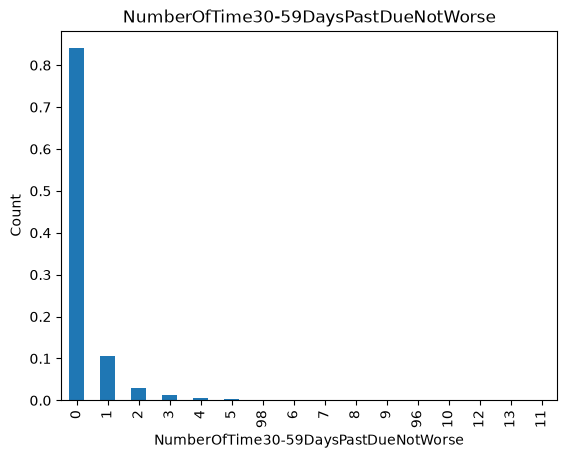

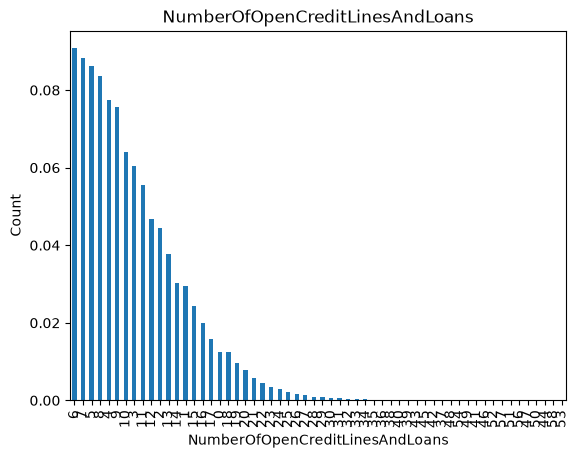

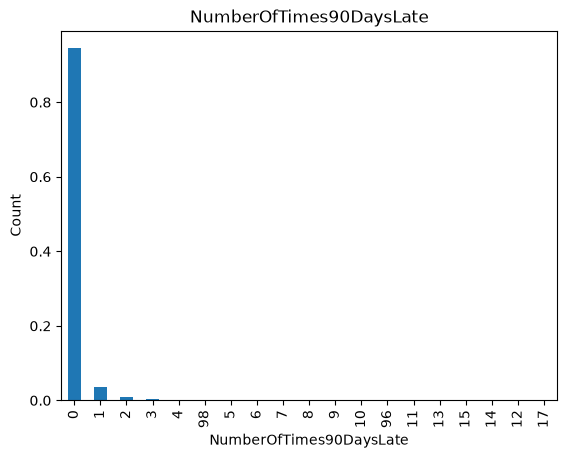

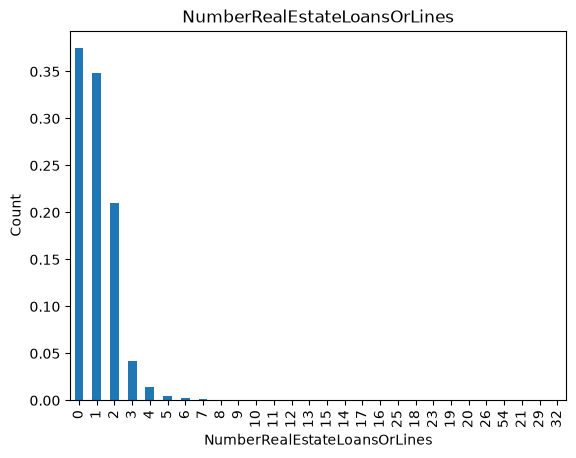

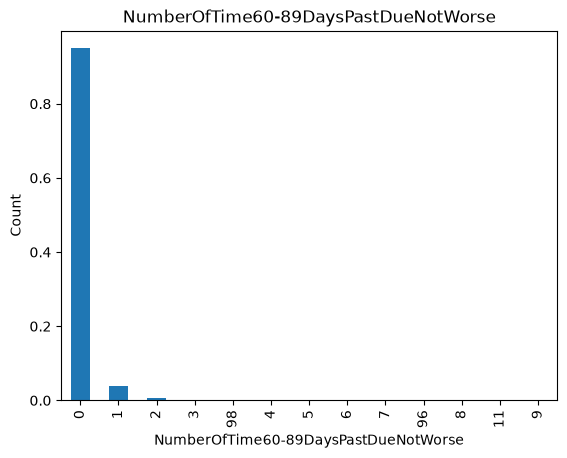

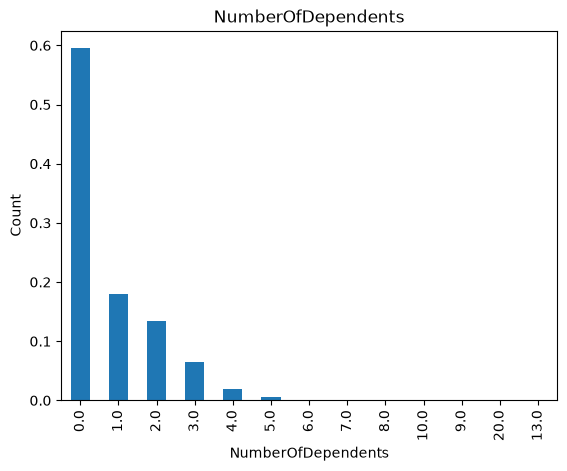

In [44]:
cols = [x for x in list(features.columns) if x.startswith('Number')]

for col in cols:
    features[col].value_counts(normalize=True).plot(kind='bar')
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

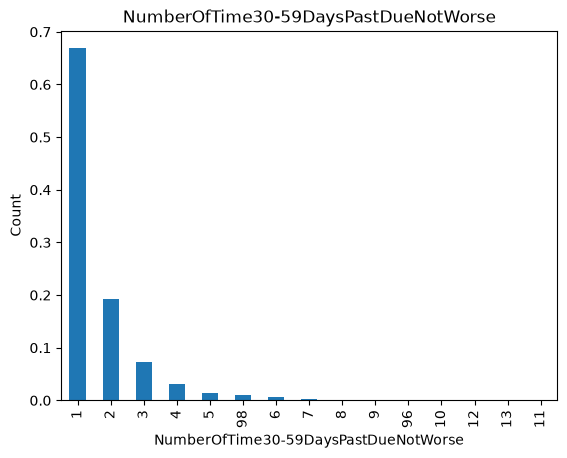

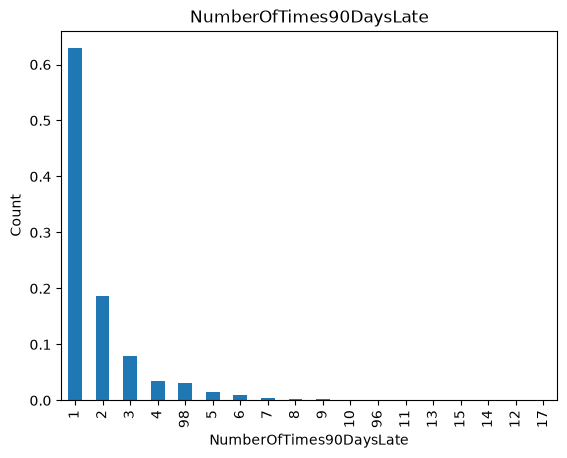

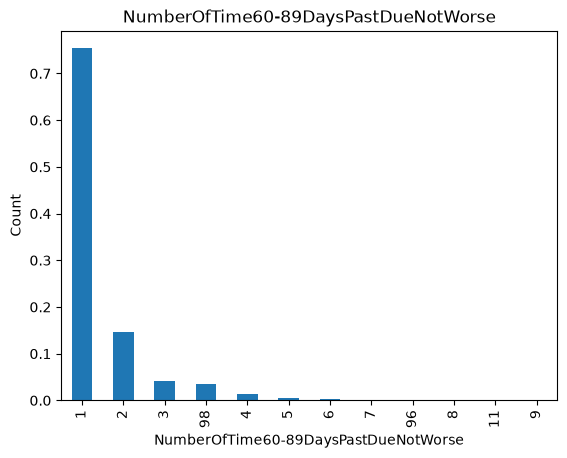

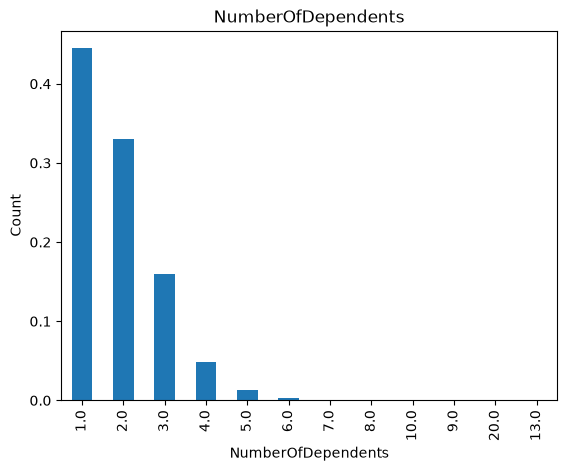

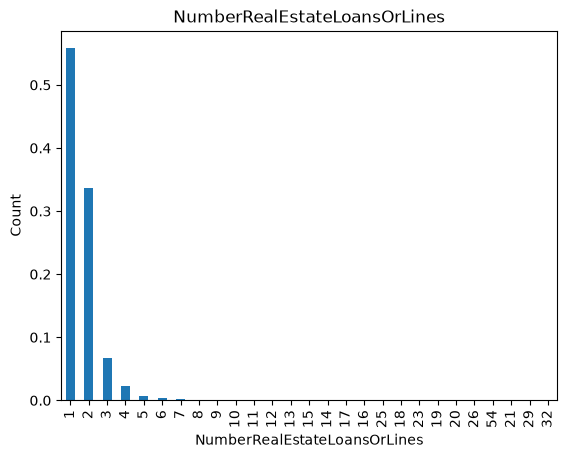

In [45]:
cols = ['NumberOfTime30-59DaysPastDueNotWorse',
        'NumberOfTimes90DaysLate',
        'NumberOfTime60-89DaysPastDueNotWorse',
        'NumberOfDependents',
        'NumberRealEstateLoansOrLines']

for col in cols:
    features[col].filter(lambda x: x != 0).value_counts(normalize=True).plot(kind='bar')
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

We define values as '> cutoff' because following an order in these variables makes sense (as it is progresively much less probable)

In [46]:
def create_categorical_feature(n, cutoff):
    m = str(n)
    if n > 90:
        m = None
    elif n > cutoff:
        m = f'> {cutoff}'
    return m

for col in cols:
    proportion = features[col].filter(lambda x: (x != 0) & (x < 90)).value_counts(normalize=True)
    cutoff = proportion[proportion >= 0.1].index.max()
    features[col + '_cat'] = features[col].apply(create_categorical_feature, args=(cutoff,))

features.drop(columns=cols, inplace=True)

/var/folders/sy/_vyfv0ls25j12wv6zykjk87r0000gn/T/ipykernel_50219/1360442716.py:14: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  features.drop(columns=cols, inplace=True)


In [47]:
features.head()

,RevolvingUtilizationOfUnsecuredLines,age,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTime30-59DaysPastDueNotWorse_cat,NumberOfTimes90DaysLate_cat,NumberOfTime60-89DaysPastDueNotWorse_cat,NumberOfDependents_cat,NumberRealEstateLoansOrLines_cat
Unnamed: 0,,,,,,,,,,
1,0.766127,45,0.802982,9120.0,13,2,0,0,2.0,> 2
2,0.957151,40,0.121876,2600.0,4,0,0,0,1.0,0
3,0.658180,38,0.085113,3042.0,2,1,1,0,0.0,0
4,0.233810,30,0.036050,3300.0,5,0,0,0,0.0,0
5,0.907239,49,0.024926,63588.0,7,1,0,0,0.0,1


In [48]:
num_features = features.select_dtypes(include=['int64', 'float64']).columns

features[num_features] = features[num_features].astype('float64')

display(features[num_features].describe())

# Number of missing values in each numerical feature
display(features[num_features].isnull().sum())

,RevolvingUtilizationOfUnsecuredLines,age,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans
count,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000
mean,6.048438,52.295207,353.005076,6.670221e+03,8.452760
std,249.755371,14.771866,2037.818523,1.438467e+04,5.145951
min,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,0.029867,41.000000,0.175074,3.400000e+03,5.000000
50%,0.154181,52.000000,0.366508,5.400000e+03,8.000000
75%,0.559046,63.000000,0.868254,8.249000e+03,11.000000
max,50708.000000,109.000000,329664.000000,3.008750e+06,58.000000


RevolvingUtilizationOfUnsecuredLines        0
age                                         0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
dtype: int64

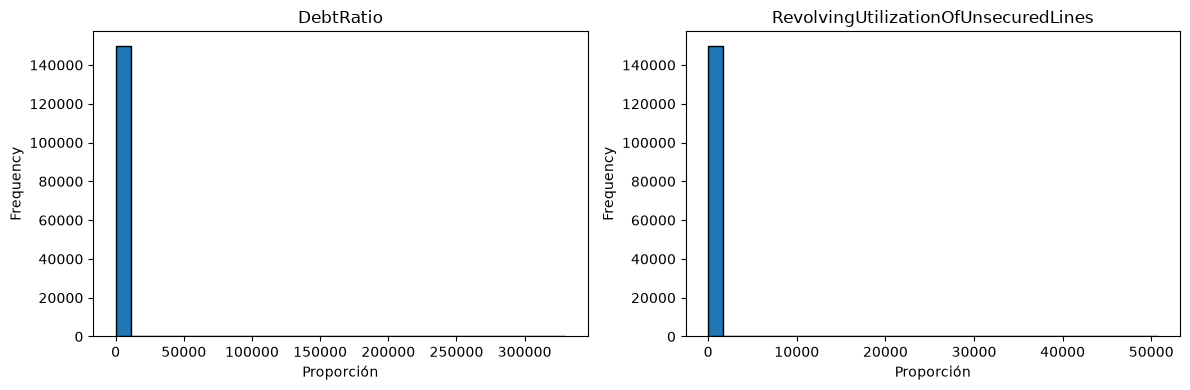

In [49]:
# Outliers in each numerical feature

perc_col = ['DebtRatio', 'RevolvingUtilizationOfUnsecuredLines']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, col in enumerate(perc_col):
    # Histograma en su propio subplot en lugar de gráfico de barras
    features[col].plot(kind='hist', bins=30, ax=axes[i], title=col, edgecolor='black')
    axes[i].set_xlabel('Proporción')

plt.tight_layout()
plt.show()

In [ ]:
IQR

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, col in enumerate(perc_col):
    # Histograma en su propio subplot en lugar de gráfico de barras
    features[col].plot(kind='hist', bins=30, ax=axes[i], title=col, edgecolor='black')
    axes[i].set_xlabel('Proporción')

plt.tight_layout()
plt.show()